# 2.1 · Reconstructing the S&P 500 from our own data

An equity **index** is a portfolio defined by a membership rule and a weighting rule; its level tracks the value of
that portfolio. Two weighting schemes matter here:

* **Capitalisation-weighted:** each constituent's weight is proportional to its (float-adjusted) market
  capitalisation, $w_i = \frac{P_i S_i}{\sum_j P_j S_j}$. The largest companies (NVIDIA, Apple, Microsoft) dominate.
  This is the **S&P 500**. Weights drift with prices automatically, so the portfolio needs no rebalancing except for
  membership and share-count changes.
* **Equal-weighted:** each constituent has weight $1/N$. This is the **S&P 500 Equal Weight** index. Its weights drift
  as prices move, so it is rebalanced back to equal every quarter, which makes it a systematic tilt towards smaller
  companies and a mild contrarian strategy (it sells recent winners and buys recent losers).

The comparisons:

| Ticker | Description | Includes dividends? |
|---|---|---|
| `^GSPC` | S&P 500 price index | no - price return only |
| `SPY` | ETF tracking the S&P 500 (expense ratio 0.09 % a year) | yes - distributed; we reinvest them |
| `^SPXEW` | S&P 500 Equal Weight price index | no |
| `RSP` | ETF tracking the equal-weight S&P 500 (expense ratio 0.20 % a year) | yes |

**Why reconstruct it?** It is an end-to-end test of the data. If a portfolio built only from our own data -
constituents on each date, prices, splits, dividends and share counts - tracks the official index closely, those
inputs are correct. And once the official methodology can be reproduced, any variant of it can be built.

In [1]:
import pandas as pd
from IPython.display import display

from equity_research import charts
from equity_research.research import indices as ix
from equity_research.research.cache import ResearchCache

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

charts.style()
cache = ResearchCache()
TODAY = pd.Timestamp.today().strftime("%Y-%m-%d")

START = "2006-01-01"
sp500 = ix.load_index_data(cache, "SP500", START, TODAY)
print(
    f"{sp500.close.shape[1]:,} companies have been in the S&P 500 since {START}; "
    f"{int(sp500.members.iloc[-1].sum())} are in it today"
)

987 companies have been in the S&P 500 since 2006-01-01; 503 are in it today


## Step 1 · Constituents and their market capitalisation

Market capitalisation = price × shares. We use **float-adjusted** shares (excluding holdings by founders,
governments and other strategic holders), because S&P weights by float. Where the float is missing we fall back on
the company's shares outstanding from its SEC filing.

The chart shows the fraction of each day's constituents we can value. A constituent we cannot value is dropped that
day and its weight is redistributed pro rata to the others.

Share counts used today: {'float': 502, '': 1}


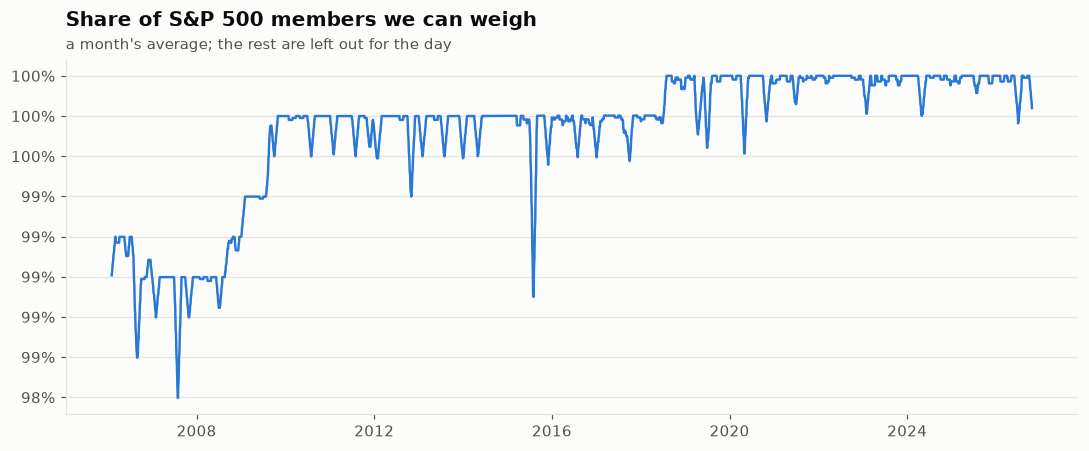

In [2]:
cap = ix.cap_weighted(sp500.price_returns, sp500.market_cap, sp500.members)
source = sp500.share_source.where(sp500.members).iloc[-1].value_counts()
print("Share counts used today:", source.to_dict())
fig = charts.lines(
    {"members we can value": cap["covered"].rolling(21).mean()},
    "Share of S&P 500 members we can weigh",
    subtitle="a month's average; the rest are left out for the day",
    percent=True,
)

The ten largest weights today. They can be checked against S&P's published factsheet: NVIDIA, Apple and Microsoft
each weigh roughly 6 to 8 %.

Together the ten weigh 38% of the index.


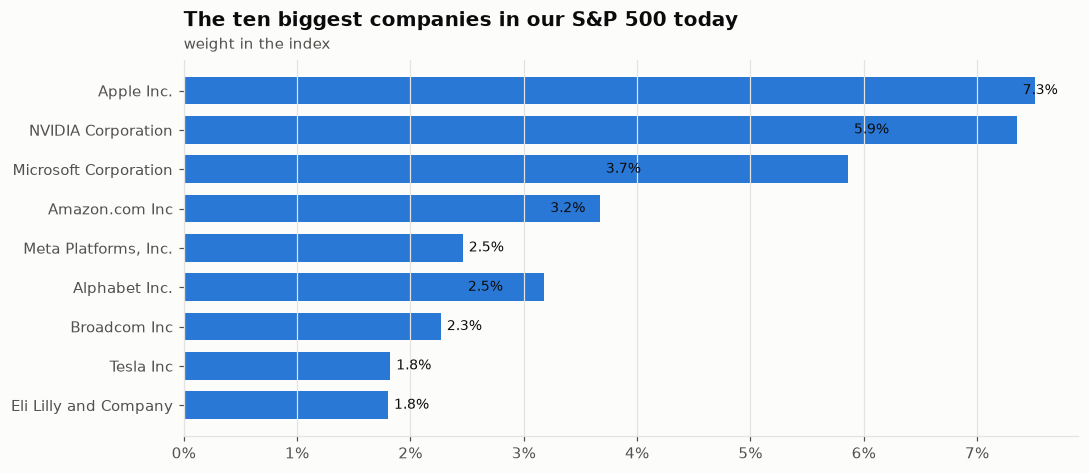

In [3]:
latest = sp500.market_cap.iloc[-1].where(sp500.members.iloc[-1]).dropna()
weights = (latest / latest.sum()).sort_values(ascending=False)
top = weights.head(10).rename(index=sp500.names)
fig = charts.ranked_bars(
    top, "The ten biggest companies in our S&P 500 today", subtitle="weight in the index", percent=True
)
print(f"Together the ten weigh {top.sum():.0%} of the index.")

## Step 2 · Cap-weighted reconstruction against the S&P 500

Each day the portfolio return is $r_{p,t} = \sum_i w_{i,t-1}\, r_{i,t}$, with weights from the previous close's market
capitalisations - exactly what an index-tracking fund earns.

* Against **^GSPC** we use price returns only (the index level excludes dividends).
* Against **SPY** we include dividends (*total return*), as the fund's holders receive them.

Two statistics summarise the fit:

* **Tracking error** - the annualised standard deviation of the daily return difference,
  $\sigma(r_p - r_b)\sqrt{252}$. A tracking error of 1 % means the two typically end a year within about 1 % of each
  other.
* **Correlation** of daily returns - close to 1 means they move together day by day.

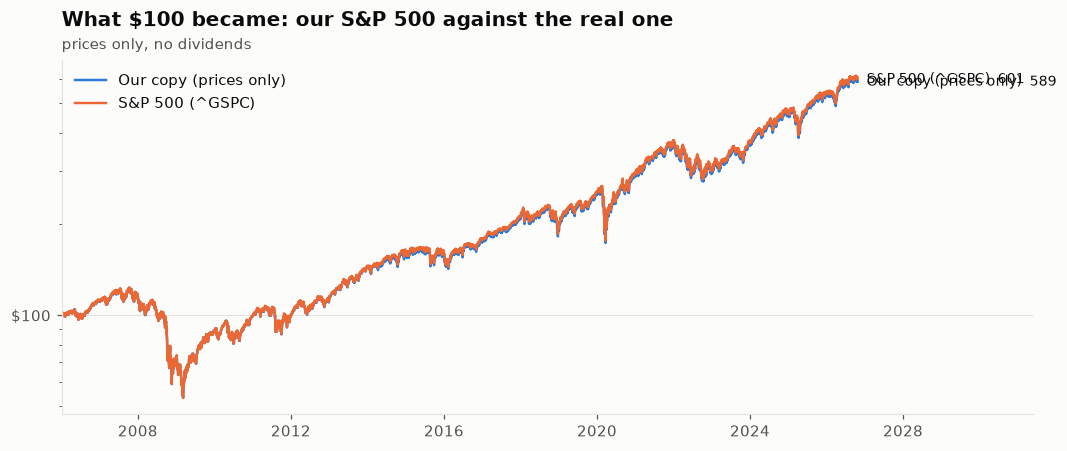

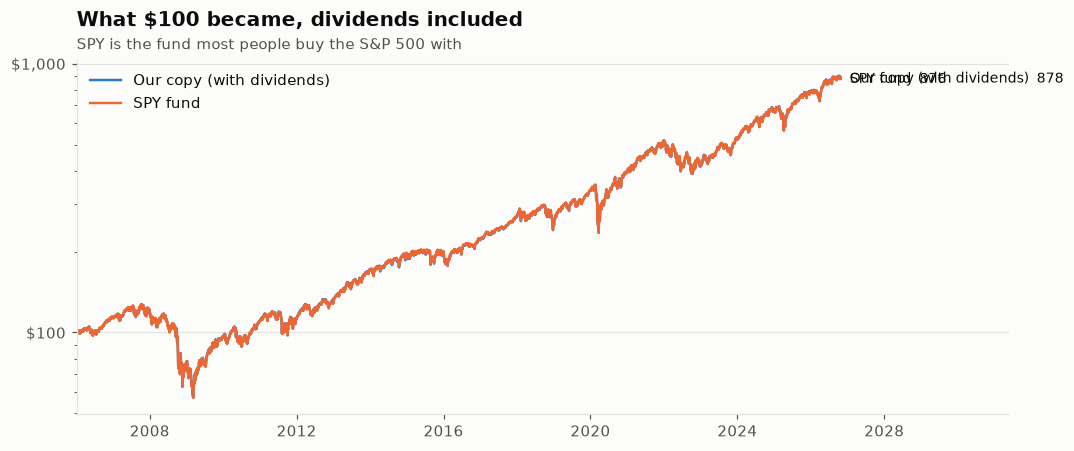

In [4]:
gspc = ix.vendor_returns(cache, "^GSPC", total=False)
spy = ix.vendor_returns(cache, "SPY", total=True)
cap_tr = ix.cap_weighted(sp500.total_returns, sp500.market_cap, sp500.members)
fig = charts.growth(
    {"Our copy (prices only)": cap["return"], "S&P 500 (^GSPC)": gspc},
    "What $100 became: our S&P 500 against the real one",
    subtitle="prices only, no dividends",
)
fig = charts.growth(
    {"Our copy (with dividends)": cap_tr["return"], "SPY fund": spy},
    "What $100 became, dividends included",
    subtitle="SPY is the fund most people buy the S&P 500 with",
)

## Step 3 · Equal-weighted reconstruction against the official index

Every constituent starts with weight $1/N$; between rebalances the weights drift with relative prices; a deletion
passes its weight to the replacing addition. At every quarter end all weights are reset to $1/N$.

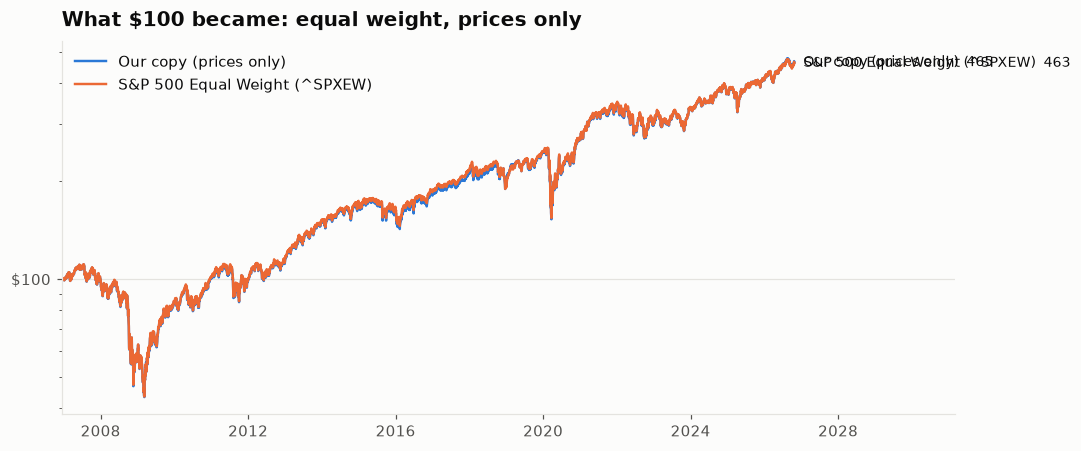

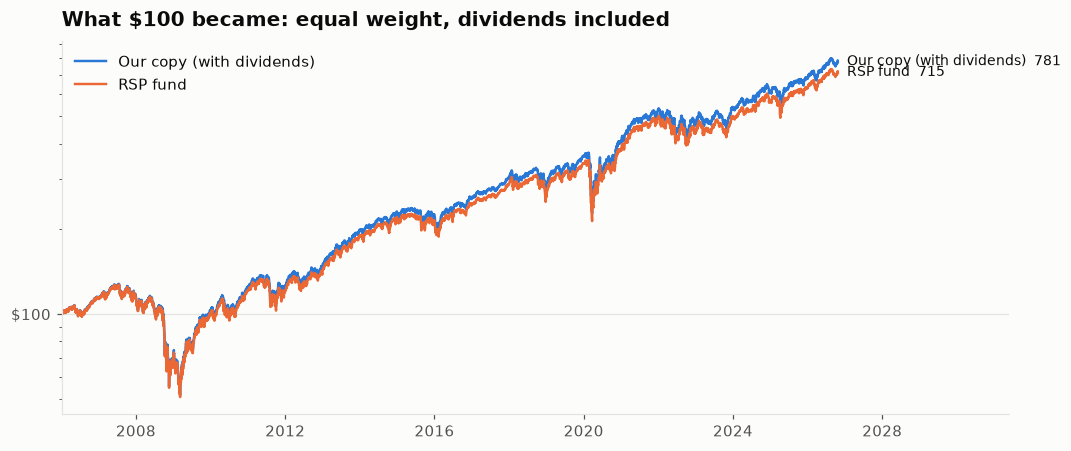

In [5]:
ew = ix.equal_weighted(sp500.price_returns, sp500.members)
ew_tr = ix.equal_weighted(sp500.total_returns, sp500.members)
spxew = ix.vendor_returns(cache, "^SPXEW", total=False)
rsp = ix.vendor_returns(cache, "RSP", total=True)
fig = charts.growth(
    {"Our copy (prices only)": ew["return"], "S&P 500 Equal Weight (^SPXEW)": spxew},
    "What $100 became: equal weight, prices only",
)
fig = charts.growth(
    {"Our copy (with dividends)": ew_tr["return"], "RSP fund": rsp},
    "What $100 became: equal weight, dividends included",
)

## Summary statistics

One row per comparison. *Per year* is the compound annual growth rate (CAGR) over the whole period.

In [6]:
pairs = {
    "market value vs ^GSPC": (cap["return"], gspc),
    "market value + dividends vs SPY": (cap_tr["return"], spy),
    "equal weight vs ^SPXEW": (ew["return"], spxew),
    "equal weight + dividends vs RSP": (ew_tr["return"], rsp),
}
summary = pd.DataFrame({name: ix.tracking(ours, theirs) for name, (ours, theirs) in pairs.items()}).T
summary["days"] = summary["days"].astype(int)
display(
    summary.style.format(
        {
            "days": "{:,}",
            "ours_per_year": "{:.2%}",
            "theirs_per_year": "{:.2%}",
            "tracking_error": "{:.2%}",
            "correlation": "{:.4f}",
            "beta": "{:.3f}",
        }
    )
)

,days,ours_per_year,theirs_per_year,tracking_error,correlation,beta
market value vs ^GSPC,"5,234",8.91%,9.02%,0.35%,0.9998,0.999
market value + dividends vs SPY,"5,234",11.03%,11.02%,2.14%,0.9938,0.998
equal weight vs ^SPXEW,"4,984",8.08%,8.05%,1.32%,0.9981,1.006
equal weight + dividends vs RSP,"5,234",10.40%,9.94%,1.97%,0.9955,1.009


Calendar-year total returns: our two reconstructions and the two ETFs.

,Our market-value copy,SPY,Our equal-weight copy,RSP
trade_date,,,,
2006,13.7%,13.8%,14.1%,13.5%
2007,5.7%,5.1%,1.4%,0.9%
2008,-37.0%,-36.8%,-39.8%,-40.1%
2009,26.7%,26.4%,45.9%,44.6%
2010,14.9%,15.1%,21.8%,21.4%
2011,2.1%,1.9%,0.3%,-0.7%
2012,16.0%,16.0%,17.5%,17.2%
2013,32.3%,32.3%,36.2%,35.5%
2014,12.3%,13.5%,14.1%,14.1%


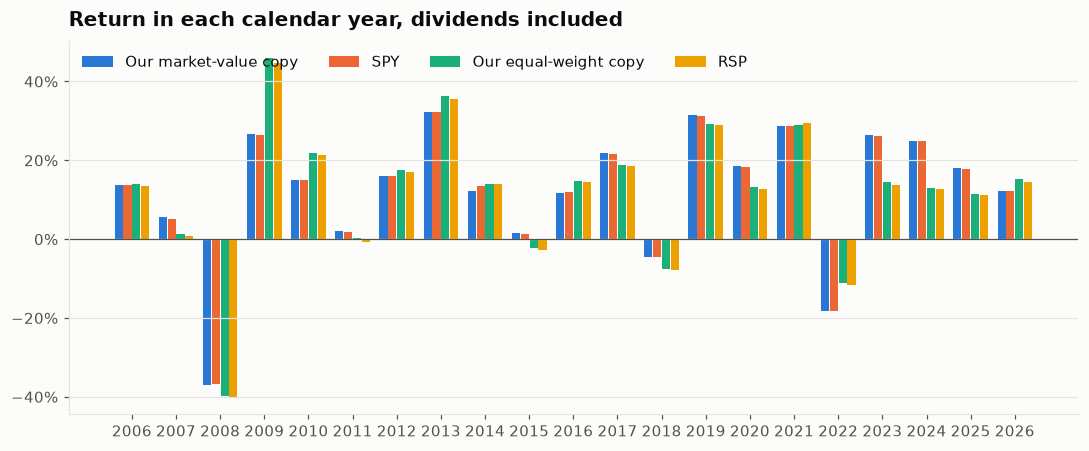

In [7]:
years = ix.calendar_years(
    {"Our market-value copy": cap_tr["return"], "SPY": spy, "Our equal-weight copy": ew_tr["return"], "RSP": rsp}
)
fig = charts.yearly_bars(years, "Return in each calendar year, dividends included")
display(years.style.format("{:.1%}"))

## Sources of tracking error

Small differences are expected, and each has an identifiable cause:

* **Fund expenses.** SPY charges 0.09 % a year and RSP 0.20 %; our reconstructions have no costs.
* **Share counts.** S&P updates share counts on a fixed schedule and rounds float factors in steps; we use the latest
  monthly figure.
* **Timing.** The official equal-weight index rebalances after the third Friday of March, June, September and
  December; we rebalance on the quarter's last trading day. Index changes take effect at a precise time that we
  approximate to the day.
* **Missing data.** A constituent we cannot value on a given day is dropped (the first chart).

A large gap in a single year points at a data error to investigate: a missed split, a wrong share count, a missing
constituent.

**Cap-weighted versus equal-weighted:** the difference between the two reconstructions is a return on *size*. When
the largest companies outperform the average constituent, the cap-weighted index beats the equal-weighted one, and
vice versa. Compare the two reconstructed bars year by year.